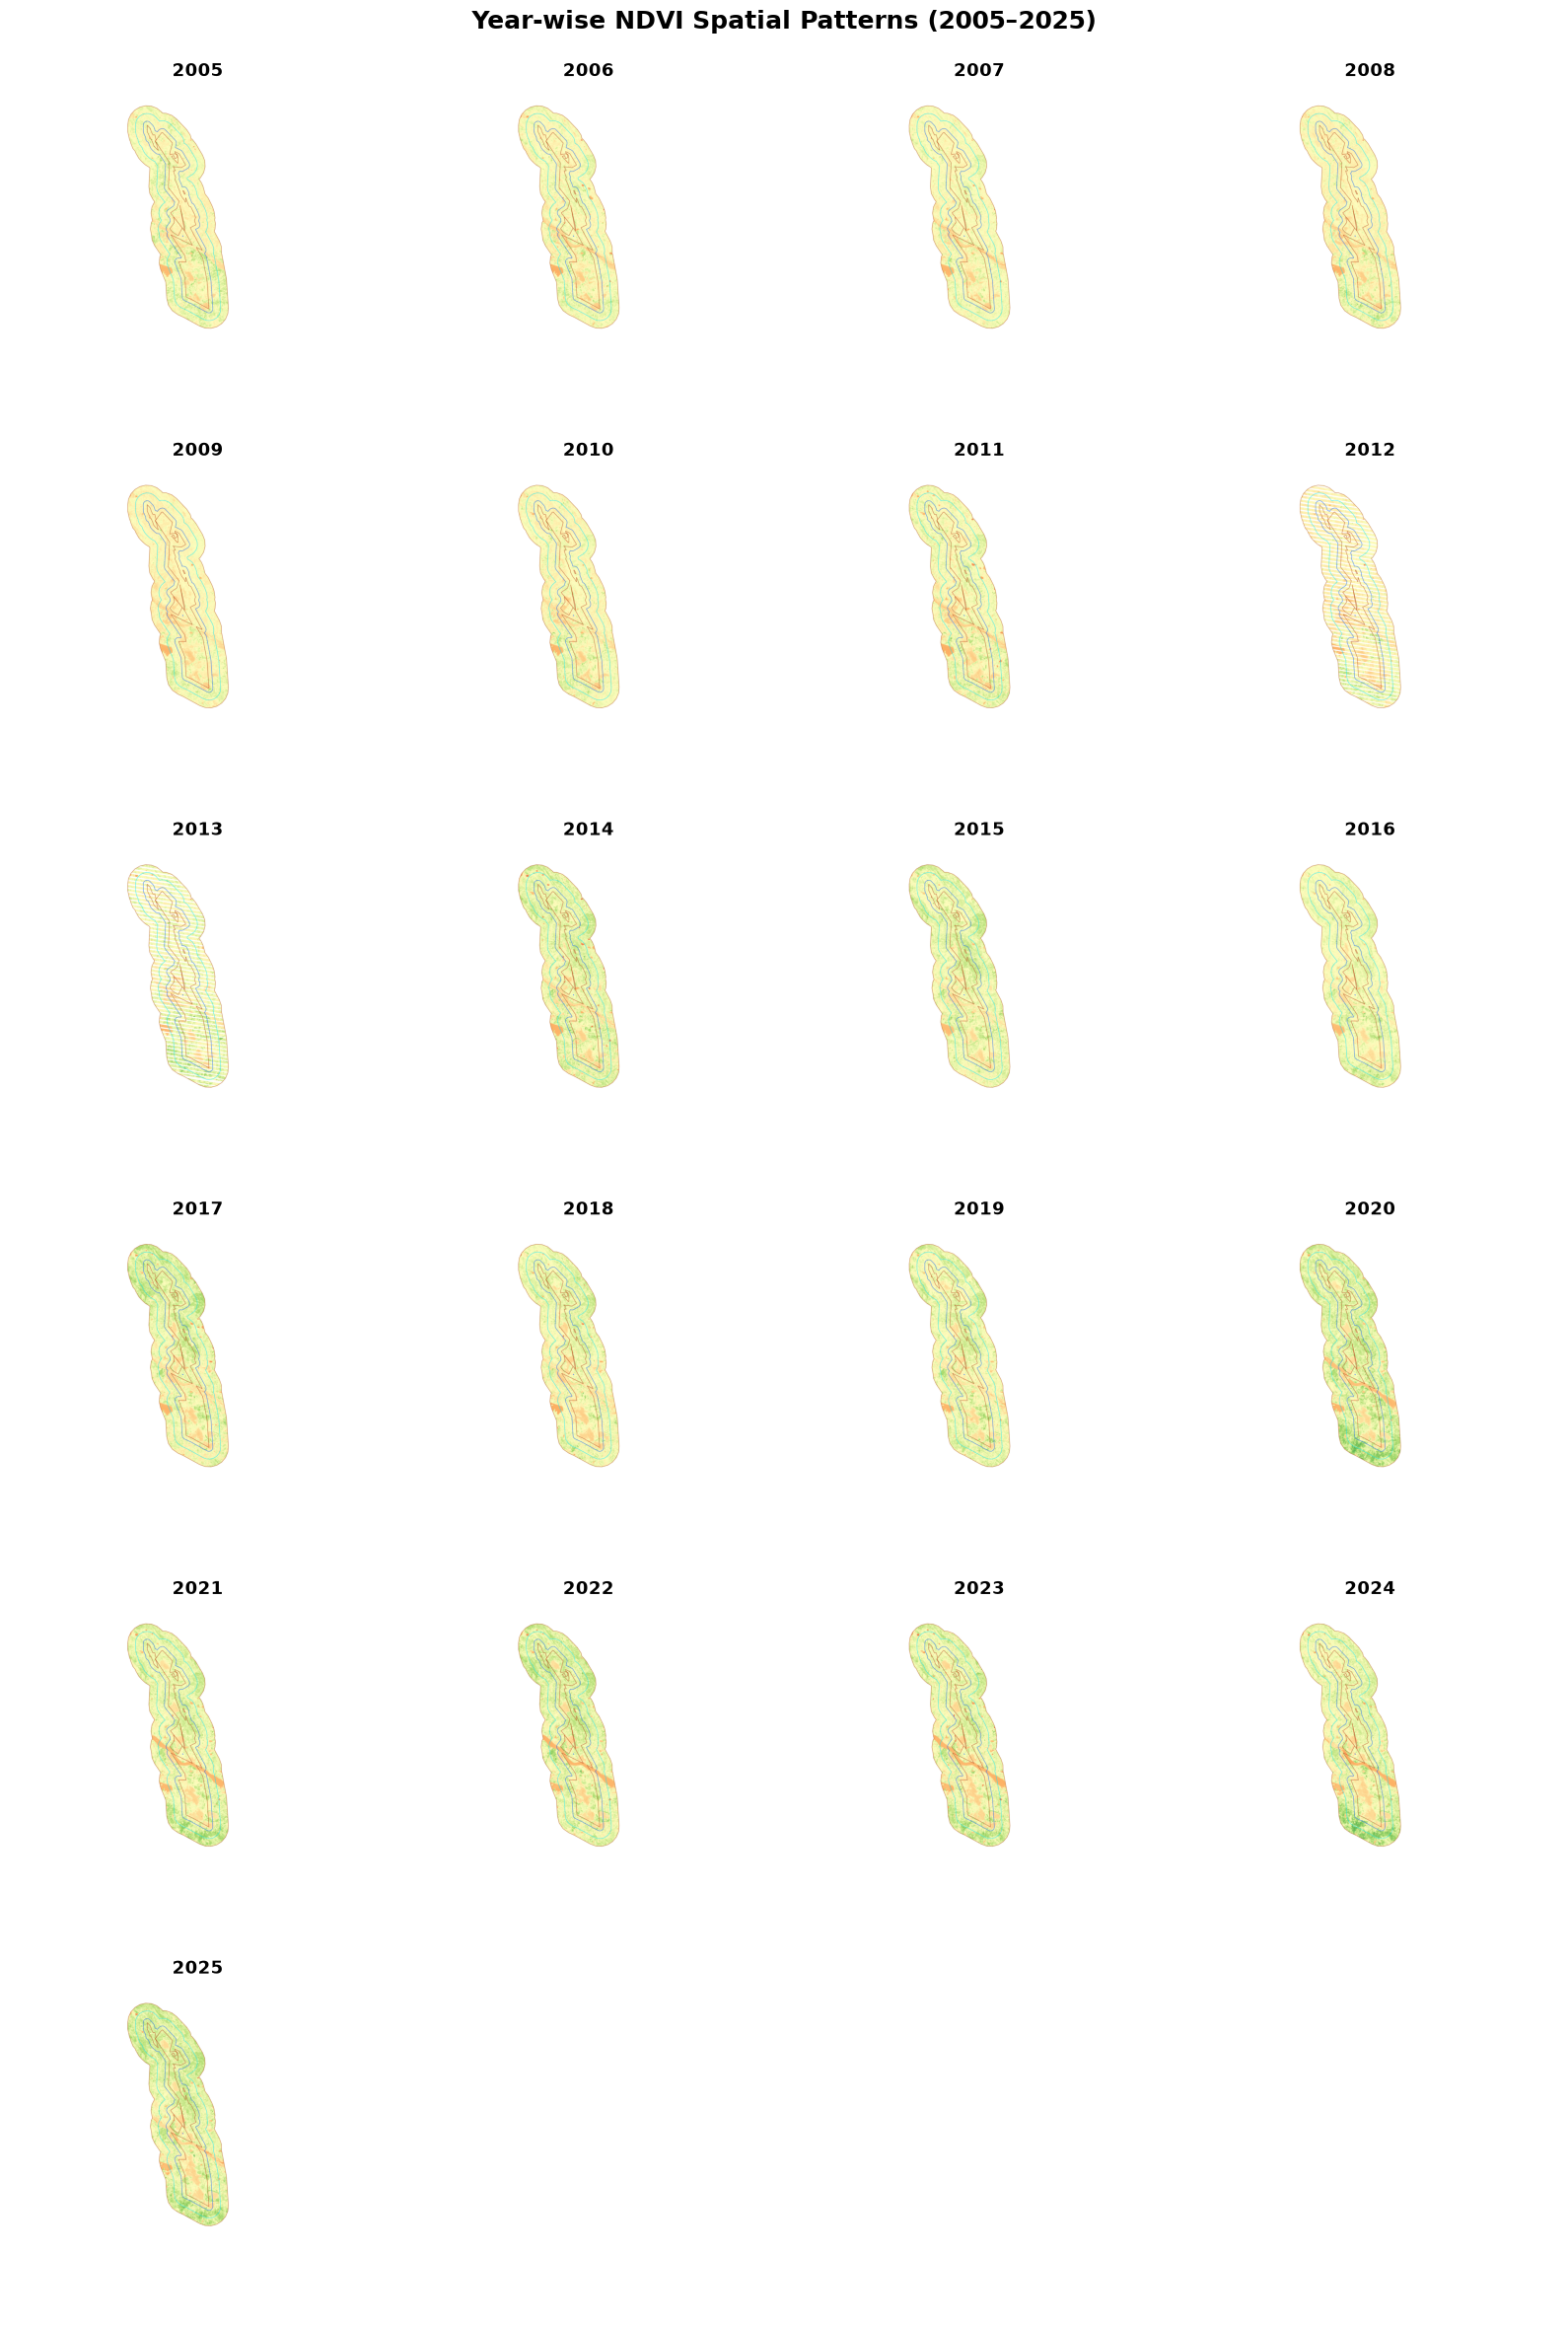

In [1]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import re
import math

# Use the same folder as the notebook
image_folder = Path(".")

# Select only year-wise NDVI spatial pattern images
image_files = []

for file in image_folder.glob("NDVI_Spatial_Pattern_*.png"):
    match = re.search(r"NDVI_Spatial_Pattern_(\d{4})\.png$", file.name)

    if match:
        year = int(match.group(1))
        if 2005 <= year <= 2025:
            image_files.append((year, file))

image_files.sort(key=lambda x: x[0])

if not image_files:
    print("No year-wise NDVI images found in the current folder.")
else:
    n_cols = 4
    n_rows = math.ceil(len(image_files) / n_cols)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(16, 4 * n_rows),
        squeeze=False
    )
    axes = axes.flatten()

    for i, (year, file) in enumerate(image_files):
        with Image.open(file) as img:
            axes[i].imshow(img.copy())

        axes[i].set_title(str(year), fontsize=13, fontweight="bold")
        axes[i].axis("off")

    for i in range(len(image_files), len(axes)):
        axes[i].axis("off")

    fig.suptitle(
        "Year-wise NDVI Spatial Patterns (2005–2025)",
        fontsize=18,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

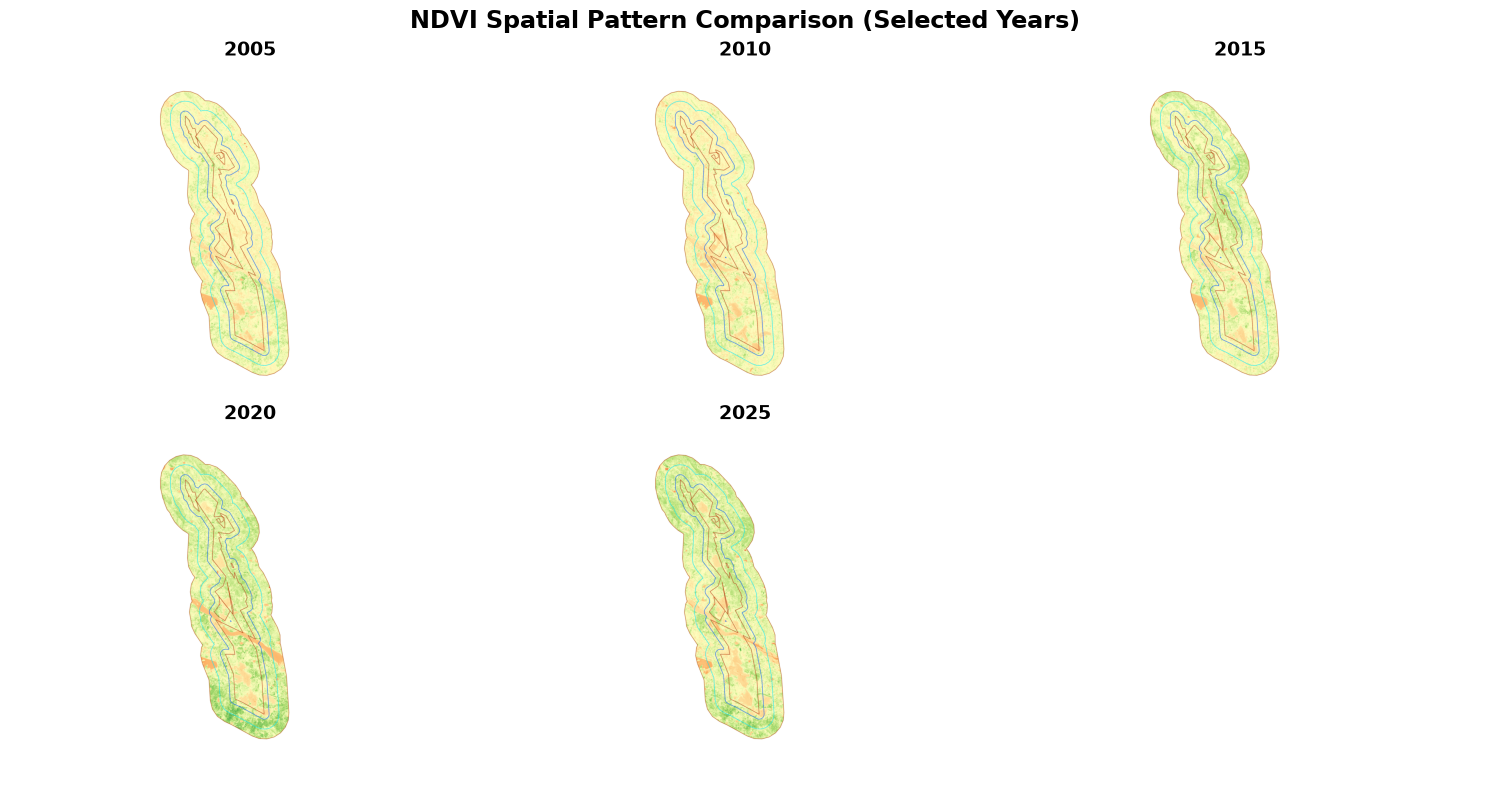

In [2]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import math

# Folder containing the images
image_folder = Path(".")

# Select specific years
selected_years = [2005, 2010, 2015, 2020, 2025]

# Create the grid
n_cols = 3
n_rows = math.ceil(len(selected_years) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(15, 8),
    squeeze=False
)
axes = axes.flatten()

for i, year in enumerate(selected_years):
    file = image_folder / f"NDVI_Spatial_Pattern_{year}.png"

    if file.exists():
        with Image.open(file) as img:
            axes[i].imshow(img.copy())

        axes[i].set_title(str(year), fontsize=14, fontweight="bold")
        axes[i].axis("off")
    else:
        axes[i].set_title(f"{year} - Image not found")
        axes[i].axis("off")

# Hide unused subplot
for i in range(len(selected_years), len(axes)):
    axes[i].axis("off")

plt.suptitle(
    "NDVI Spatial Pattern Comparison (Selected Years)",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

C:\conda_tmp\ipykernel_22568\1047257845.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


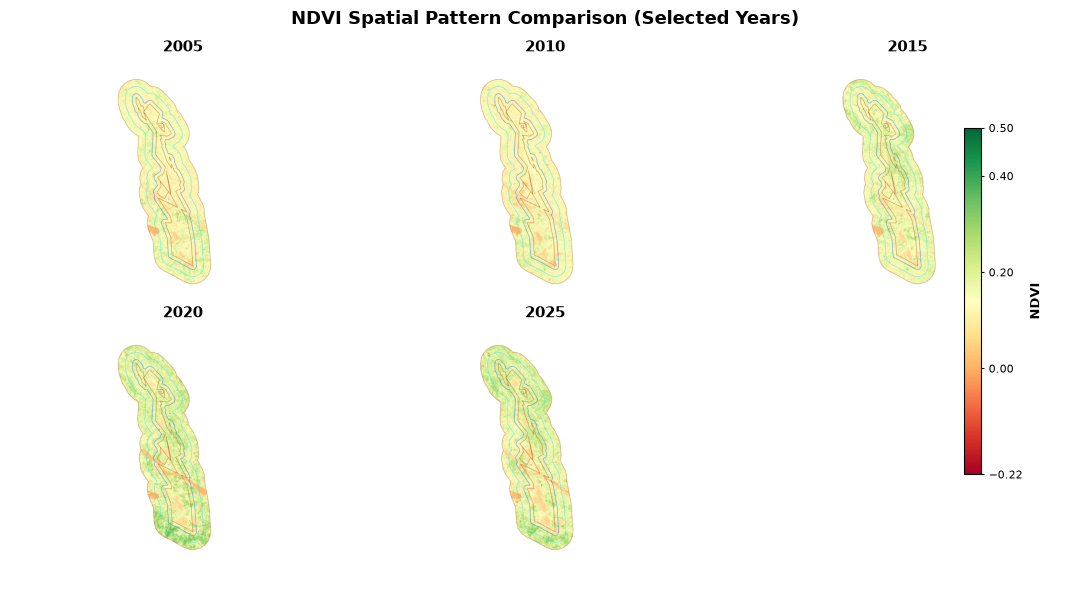

In [4]:

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from PIL import Image
from pathlib import Path
import math

# Folder containing the images
image_folder = Path(".")

# Selected years
selected_years = [2005, 2010, 2015, 2020, 2025]

# NDVI range
vmin = -0.22
vmax = 0.50

# Red -> Yellow -> Green
cmap = plt.cm.RdYlGn
norm = Normalize(vmin=vmin, vmax=vmax)

# Create a compact grid
n_cols = 3
n_rows = math.ceil(len(selected_years) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(11, 6),
    squeeze=False
)

axes = axes.flatten()

# Plot the images
for i, year in enumerate(selected_years):
    file = image_folder / f"NDVI_Spatial_Pattern_{year}.png"

    if file.exists():
        with Image.open(file) as img:
            axes[i].imshow(img.copy())

        axes[i].set_title(
            str(year),
            fontsize=11,
            fontweight="bold"
        )
        axes[i].axis("off")

    else:
        axes[i].set_title(
            f"{year} - Image not found",
            fontsize=9
        )
        axes[i].axis("off")

# Hide unused subplot
for i in range(len(selected_years), len(axes)):
    axes[i].axis("off")

# Create the NDVI color bar
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes.tolist(),
    orientation="vertical",
    fraction=0.025,
    pad=0.015,
    shrink=0.75
)

# Color bar formatting
cbar.set_label(
    "NDVI",
    fontsize=9,
    fontweight="bold",
    labelpad=5
)

cbar.set_ticks([-0.22, 0.00, 0.20, 0.40, 0.50])
cbar.ax.tick_params(labelsize=8, length=2)

# Main title
fig.suptitle(
    "NDVI Spatial Pattern Comparison (Selected Years)",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()
